# The perfectns validation problems

The `ultranest.perfectns` module provides likelihood/prior pairs with
**analytic evidence values** (`analytic_lnZ`), designed for validating
nested samplers: because the correct `lnZ` is known, any sampler can be
scored against it.

This notebook shows all five problems, visualises their shape in 2d, and
tabulates the analytic `lnZ` values across dimensionalities.

The problems plug into any nested sampler through their `transform`
(uniform prior on $[0,1]^N$) and `loglike` functions; the pipeline in
`evaluate/perfectns/` drives them in batches.

## The problems

* **NonIsotropicGaussian** – flat prior on $[0,1]^N$ and an anisotropic
  gaussian likelihood whose widths span decades. Normalized, so
  $\ln Z \approx 0$ when the cube contains the bulk of the gaussian.
* **UncorrelatedFunnel** – a funnel: the first dimension scales the width
  of all others (a hierarchical model like $\mu \sim \mathcal{N}(0,
  \sigma)$ with per-point widths). Truncated to the cube; its evidence
  underflows ($-\infty$) at high dimensionality.
* **BoxGaussian** – a constant (uniform) likelihood inside a box; the
  evidence is the box volume times its height, so `lnZ` is large and
  positive.
* **Banana** – the curved banana: a triangular, constant-Jacobian map
  bends the gaussian into a banana body. The analytic value is a 2d
  numerical integration, implemented for $d=2$ only.
* **HyperPyramid** – a hyper-pyramid (uniform inside a simplex-like
  shape that tightens with each dimension).


## Shape of the problems in 2d

Each panel shows the log-likelihood over the unit square for $d=2$ (the
prior is the flat unit cube, so this is the full picture).

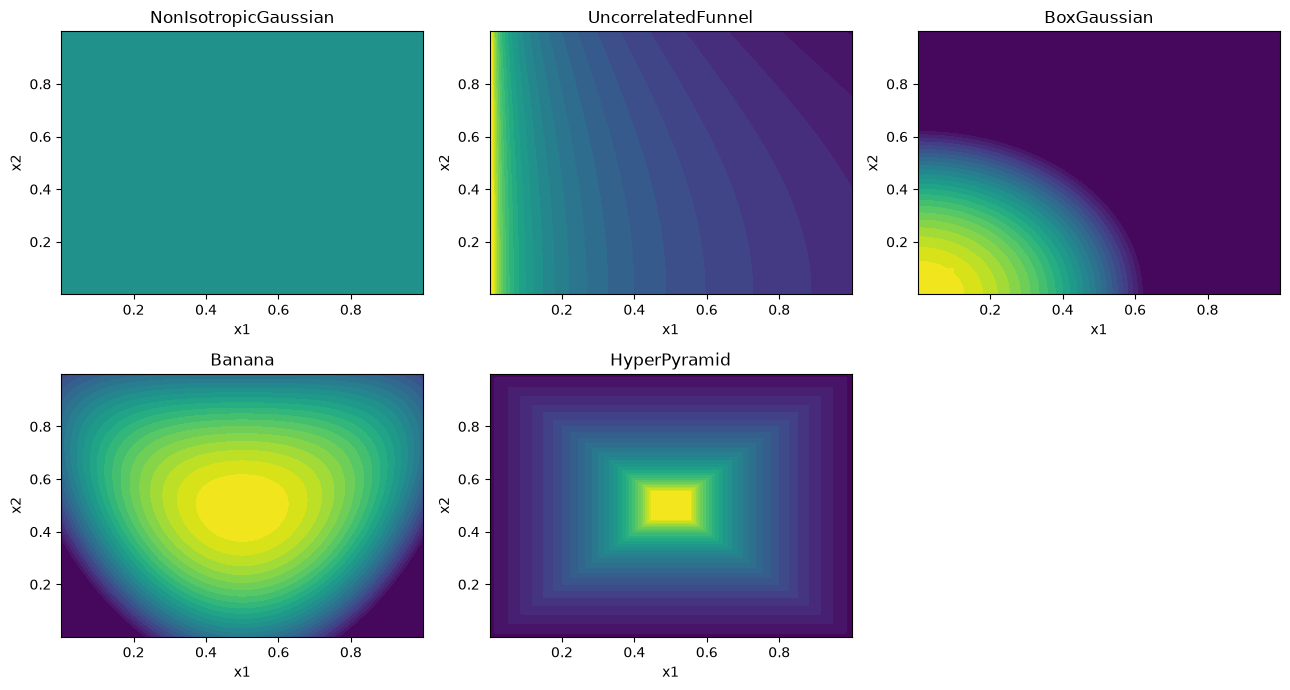

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

from ultranest.perfectns import (
    BananaGaussianLRPS, BoxGaussianLRPS, HyperPyramidLRPS,
    NonIsotropicGaussianLRPS, UncorrelatedFunnelLRPS)

problems = [
    ('NonIsotropicGaussian',
     lambda d: NonIsotropicGaussianLRPS(d)),
    ('UncorrelatedFunnel',
     lambda d: UncorrelatedFunnelLRPS(d, trunc_sigmas=6.0)),
    ('BoxGaussian', lambda d: BoxGaussianLRPS(d)),
    ('Banana', lambda d: BananaGaussianLRPS.standard_problem(d)),
    ('HyperPyramid', lambda d: HyperPyramidLRPS(d)),
]

grid = np.linspace(1e-6, 1 - 1e-6, 301)
X, Y = np.meshgrid(grid, grid)
pts = np.stack([X.flatten(), Y.flatten()], axis=1)

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, (name, make) in zip(axes.flatten(), problems):
    L = make(2).loglike(pts).reshape(X.shape)
    vmax = np.percentile(L[np.isfinite(L)], 99)
    ax.contourf(X, Y, np.clip(L, -20, vmax), levels=30)
    ax.set_title(name)
    ax.set_xlabel('x1')
    ax.set_ylabel('x2')
axes.flatten()[-1].axis('off')
plt.tight_layout()


The gaussian problems are smooth ellipsoids (the NonIsotropicGaussian
strongly anisotropic, the funnel with a curved width profile), the box is
flat with sharp edges, the banana is curved, and the pyramid is
piecewise-linear.

## Analytic lnZ values across dimensionality

`analytic_lnZ()` gives the reference value a nested sampler should
recover. Notes:

* the **banana** value is a 2d numerical integration and raises for
  $d \neq 2$ (marked `NaN`);
* the **funnel** evidence underflows to $-\infty$ from $d=30$ on: the
  truncated likelihood vanishes everywhere in the cube at those widths;
* the NonIsotropicGaussian is normalized and its bulk lies inside the
  cube, so its `lnZ` stays at $\approx 0$; the box concentrates its
  probability mass, so its `lnZ` is large and positive.

In [2]:
import pandas as pd

dims = [1, 2, 3, 4, 5, 7, 10, 15, 20, 30, 40]
rows = {}
for name, make in problems:
    vals = []
    for d in dims:
        try:
            vals.append(float(make(d).analytic_lnZ()))
        except Exception:
            vals.append(np.nan)
    rows[name] = vals

df = pd.DataFrame.from_dict(rows, orient='index', columns=dims)
df.index.name = 'problem'
df.round(3)


/tmp/ultranest-snowball9/ultranest/perfectns.py:664: RuntimeWarning: divide by zero encountered in log1p
  log_phidiff = special.log_ndtr(usr) + np.log1p(


,1,2,3,4,5,7,10,15,20,30,40
problem,,,,,,,,,,,
NonIsotropicGaussian,0.000,-0.000,-0.000,-0.000,-0.000,-0.000,-0.000,-0.000,-0.000,-0.000,-0.000
UncorrelatedFunnel,-2.871,-5.491,-7.862,-9.983,-11.854,-14.851,-17.630,-19.517,-20.275,-inf,-inf
BoxGaussian,97.541,95.083,92.624,90.166,87.707,82.790,75.415,63.122,50.830,26.245,1.660
Banana,NaN,-2.769,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
HyperPyramid,-0.983,-0.988,-0.990,-0.991,-0.991,-0.992,-0.992,-0.992,-0.993,-0.993,-0.993


## Using the problems

Each problem exposes `paramnames`, `transform(u)` and
`loglike(theta)` (vectorized), plus `analytic_lnZ()` and
`make_volume_function()`. They are the standard way to test a nested
sampler end to end: run the sampler and compare its `lnZ` against the
table above.